# Practical No. 03: Autoencoder and Variational Autoencoder for Image Reconstruction

## Aim
Build an **Autoencoder (AE)** and a **Variational Autoencoder (VAE)** for image **reconstruction** and **generation**, and **compare** both models by analysing the quality of reconstructed and generated images.

## Theory

**Autoencoder (AE)** – a neural network trained to copy its input to its output through a narrow *bottleneck*.

`Image → Encoder → latent code z (small vector) → Decoder → Reconstructed image`

* Loss = reconstruction error between input and output.
* Each image is mapped to **one fixed point** in latent space. The latent space is *not regularised*, so there can be large "holes" where the decoder has never been trained.

**Variational Autoencoder (VAE)** – a *probabilistic* autoencoder.

`Image → Encoder → (μ, log σ²) → sample z = μ + σ·ε  (ε ~ N(0,1)) → Decoder → Reconstructed image`

* The encoder outputs a **distribution** (mean μ and variance σ²) instead of a single point.
* The **reparameterisation trick** (z = μ + σ·ε) lets gradients flow through the random sampling.
* Loss = **Reconstruction loss + KL divergence**

$$\mathcal{L} = \underbrace{\text{BCE}(x,\hat{x})}_{\text{reconstruction}} \; + \; \underbrace{-\tfrac12\sum\left(1+\log\sigma^2-\mu^2-\sigma^2\right)}_{\text{KL}(q(z|x)\,\|\,N(0,1))}$$

* The KL term pushes the latent space towards a smooth standard normal N(0,1), so we can **sample random z and generate new images**.

| | Autoencoder | Variational Autoencoder |
|---|---|---|
| Latent code | single point | distribution (μ, σ) |
| Loss | reconstruction | reconstruction + KL |
| Reconstruction | usually sharper | usually blurrier |
| Generation of new images | poor (latent space has holes) | good (smooth, regularised latent space) |

**Dataset:** MNIST handwritten digits (60,000 train + 10,000 test images, 28×28 grey-scale).

## Step 1: Import Libraries

In [1]:
import os, gzip, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
warnings.filterwarnings("ignore")

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Step 2: Load the MNIST Dataset
We first try the built-in Keras loader. If there is no access to the Keras server, the same files are downloaded from a GitHub mirror.

In [2]:
def load_mnist_github():
    base = "https://github.com/golbin/TensorFlow-MNIST/raw/master/mnist/data/"
    def read(name, image):
        if not os.path.exists(name + ".gz"):
            urllib.request.urlretrieve(base + name + ".gz", name + ".gz")
        with gzip.open(name + ".gz", "rb") as f:
            data = np.frombuffer(f.read(), np.uint8, offset=16 if image else 8)
        return data.reshape(-1, 28, 28) if image else data
    return ((read("train-images-idx3-ubyte", True), read("train-labels-idx1-ubyte", False)),
            (read("t10k-images-idx3-ubyte", True),  read("t10k-labels-idx1-ubyte", False)))

try:
    (x_train_raw, y_train_raw), (x_test_raw, y_test) = keras.datasets.mnist.load_data()
    print("Loaded using keras.datasets")
except Exception:
    (x_train_raw, y_train_raw), (x_test_raw, y_test) = load_mnist_github()
    print("Loaded using GitHub mirror")

print("Train images:", x_train_raw.shape, "| Test images:", x_test_raw.shape)
print("Pixel range :", x_train_raw.min(), "to", x_train_raw.max())

Loaded using GitHub mirror
Train images: (60000, 28, 28) | Test images: (10000, 28, 28)
Pixel range : 0 to 255


## Step 3: Visualise Sample Images

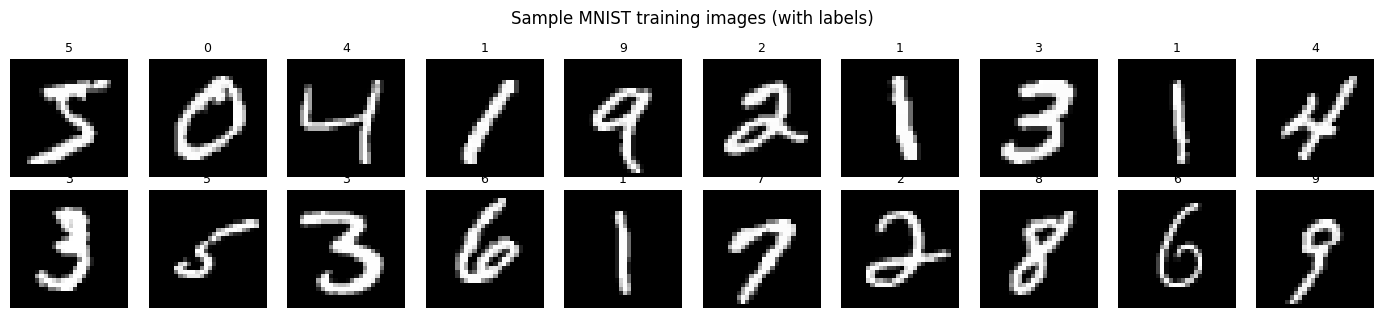

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x_train_raw[i], cmap="gray"); ax.set_title(int(y_train_raw[i]), fontsize=9); ax.axis("off")
plt.suptitle("Sample MNIST training images (with labels)"); plt.tight_layout(); plt.show()

## Step 4: Pre-processing
1. **Normalise** pixel values from 0–255 to 0–1 (the decoder's last layer uses sigmoid, whose output is in 0–1).
2. **Flatten** each 28×28 image to a 784-length vector (we use fully-connected layers).
3. Keep 5,000 training images aside as a **validation set**; the 10,000 test images are used only for the final comparison.

In [4]:
x_all  = x_train_raw.astype("float32").reshape(-1, 784) / 255.0
x_test = x_test_raw.astype("float32").reshape(-1, 784) / 255.0
y_all  = y_train_raw

x_train, x_val = x_all[:55000], x_all[55000:]
y_train, y_val = y_all[:55000], y_all[55000:]

print("Train:", x_train.shape, "| Validation:", x_val.shape, "| Test:", x_test.shape)

# Helper to display images in a row/grid
def show_row(images, titles=None, n=10, cmap="gray", figsize=(14, 1.8)):
    fig, axes = plt.subplots(1, n, figsize=figsize)
    for i in range(n):
        axes[i].imshow(images[i].reshape(28, 28), cmap=cmap); axes[i].axis("off")
        if titles is not None: axes[i].set_title(titles[i], fontsize=8)
    plt.show()

EPOCHS, BATCH, LATENT = 30, 256, 16
print("Settings -> epochs:", EPOCHS, "| batch size:", BATCH, "| latent dimension:", LATENT)

Train: (55000, 784) | Validation: (5000, 784) | Test: (10000, 784)
Settings -> epochs: 30 | batch size: 256 | latent dimension: 16


## Step 5: Build the Autoencoder (AE)

| Part | Layers |
|---|---|
| **Encoder** | 784 → Dense(256, ReLU) → Dense(64, ReLU) → Dense(latent) |
| **Decoder** | latent → Dense(64, ReLU) → Dense(256, ReLU) → Dense(784, **sigmoid**) |

The bottleneck forces the network to compress 784 pixels into only **16 numbers**. The loss is **binary cross-entropy** between the original and reconstructed pixels; we also track MSE.

In [5]:
def build_autoencoder(latent_dim):
    encoder = keras.Sequential([
        layers.Input(shape=(784,)),
        layers.Dense(256, activation="relu"),
        layers.Dense(64,  activation="relu"),
        layers.Dense(latent_dim, name="latent")
    ], name="ae_encoder")

    decoder = keras.Sequential([
        layers.Input(shape=(latent_dim,)),
        layers.Dense(64,  activation="relu"),
        layers.Dense(256, activation="relu"),
        layers.Dense(784, activation="sigmoid")
    ], name="ae_decoder")

    inp = keras.Input(shape=(784,))
    autoencoder = keras.Model(inp, decoder(encoder(inp)), name="autoencoder")
    autoencoder.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["mse"])
    return autoencoder, encoder, decoder

ae, ae_encoder, ae_decoder = build_autoencoder(LATENT)
ae.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_encoder (Sequential)         │ (None, 16)             │       218,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ae_decoder (Sequential)         │ (None, 784)            │       219,216 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 437,664 (1.67 MB)

 Trainable params: 437,664 (1.67 MB)

 Non-trainable params: 0 (0.00 B)

## Step 6: Train the Autoencoder
The input and the target are the **same image** (`x → x`), so no labels are needed (unsupervised learning).

In [6]:
hist_ae = ae.fit(x_train, x_train, validation_data=(x_val, x_val),
                 epochs=EPOCHS, batch_size=BATCH, shuffle=True, verbose=2)

Epoch 1/30


215/215 - 4s - 19ms/step - loss: 0.2365 - mse: 0.0580 - val_loss: 0.1629 - val_mse: 0.0334


Epoch 2/30


215/215 - 3s - 12ms/step - loss: 0.1446 - mse: 0.0273 - val_loss: 0.1318 - val_mse: 0.0229


Epoch 3/30


...

215/215 - 3s - 13ms/step - loss: 0.0927 - mse: 0.0102 - val_loss: 0.0940 - val_mse: 0.0104


Epoch 29/30


215/215 - 5s - 24ms/step - loss: 0.0925 - mse: 0.0101 - val_loss: 0.0938 - val_mse: 0.0104


Epoch 30/30


215/215 - 5s - 23ms/step - loss: 0.0922 - mse: 0.0101 - val_loss: 0.0936 - val_mse: 0.0103


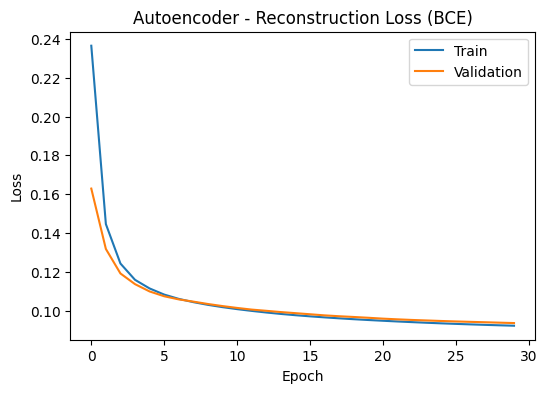

Final train loss: 0.0922 | Final validation loss: 0.0936


In [7]:
h = pd.DataFrame(hist_ae.history)
plt.figure(figsize=(6, 4))
plt.plot(h["loss"], label="Train"); plt.plot(h["val_loss"], label="Validation")
plt.title("Autoencoder - Reconstruction Loss (BCE)"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()
print(f"Final train loss: {h['loss'].iloc[-1]:.4f} | Final validation loss: {h['val_loss'].iloc[-1]:.4f}")

## Step 7: Build the Variational Autoencoder (VAE)

**Encoder** outputs *two* vectors – `z_mean` (μ) and `z_log_var` (log σ²) – and a **Sampling layer** applies the reparameterisation trick `z = μ + exp(0.5·log σ²) · ε`.

**Decoder** has the same structure as the AE decoder.

The custom `VAE` class overrides `train_step` / `test_step` to compute the **total loss = reconstruction loss + KL divergence**.

In [8]:
class Sampling(layers.Layer):
    """Reparameterisation trick: z = mean + sigma * epsilon"""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * eps


class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder, self.decoder, self.beta = encoder, decoder, beta
        self.total_tracker = keras.metrics.Mean(name="loss")
        self.recon_tracker = keras.metrics.Mean(name="recon_loss")
        self.kl_tracker    = keras.metrics.Mean(name="kl_loss")
        self.mse_tracker   = keras.metrics.Mean(name="mse")

    @property
    def metrics(self):
        return [self.total_tracker, self.recon_tracker, self.kl_tracker, self.mse_tracker]

    def call(self, x):                       # used for model(x) / predict
        z_mean, z_log_var, z = self.encoder(x)
        return self.decoder(z)

    def _compute_losses(self, x):
        z_mean, z_log_var, z = self.encoder(x)
        x_hat = self.decoder(z)
        # reconstruction loss: BCE summed over the 784 pixels, averaged over the batch
        recon = tf.reduce_mean(keras.losses.binary_crossentropy(x, x_hat)) * 784.0
        # KL divergence between N(mu, sigma^2) and N(0, 1)
        kl = -0.5 * tf.reduce_mean(tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1))
        mse = tf.reduce_mean(tf.square(x - x_hat))
        return recon + self.beta * kl, recon, kl, mse

    def _update_metrics(self, total, recon, kl, mse):
        self.total_tracker.update_state(total); self.recon_tracker.update_state(recon)
        self.kl_tracker.update_state(kl);       self.mse_tracker.update_state(mse)
        return {m.name: m.result() for m in self.metrics}

    def train_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data
        with tf.GradientTape() as tape:
            total, recon, kl, mse = self._compute_losses(x)
        grads = tape.gradient(total, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        return self._update_metrics(total, recon, kl, mse)

    def test_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data
        return self._update_metrics(*self._compute_losses(x))


def build_vae(latent_dim):
    enc_in = keras.Input(shape=(784,))
    x = layers.Dense(256, activation="relu")(enc_in)
    x = layers.Dense(64,  activation="relu")(x)
    z_mean    = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    z = Sampling(name="z")([z_mean, z_log_var])
    encoder = keras.Model(enc_in, [z_mean, z_log_var, z], name="vae_encoder")

    decoder = keras.Sequential([
        layers.Input(shape=(latent_dim,)),
        layers.Dense(64,  activation="relu"),
        layers.Dense(256, activation="relu"),
        layers.Dense(784, activation="sigmoid")
    ], name="vae_decoder")

    vae = VAE(encoder, decoder, name="vae")
    vae.compile(optimizer=keras.optimizers.Adam(1e-3))
    return vae, encoder, decoder

vae, vae_encoder, vae_decoder = build_vae(LATENT)
vae_encoder.summary()
vae_decoder.summary()

Model: "vae_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 784)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 256)       │    200,960 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │     16,448 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 16)        │      1,040 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 16)        │      1,040 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Sampling)        │ (None, 16)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 219,488 (857.38 KB)

 Trainable params: 219,488 (857.38 KB)

 Non-trainable params: 0 (0.00 B)

Model: "vae_decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 219,216 (856.31 KB)

 Trainable params: 219,216 (856.31 KB)

 Non-trainable params: 0 (0.00 B)

## Step 8: Train the VAE
We train for the same number of epochs and with the same batch size as the AE, so the comparison is fair.

In [9]:
hist_vae = vae.fit(x_train, x_train, validation_data=(x_val, x_val),
                   epochs=EPOCHS, batch_size=BATCH, shuffle=True, verbose=2)

Epoch 1/30


215/215 - 5s - 21ms/step - kl_loss: 8.5348 - loss: 205.1105 - mse: 0.0628 - recon_loss: 196.5758 - val_kl_loss: 12.2123 - val_loss: 159.5031 - val_mse: 0.0419 - val_recon_loss: 147.2908


Epoch 2/30


215/215 - 3s - 12ms/step - kl_loss: 14.2290 - loss: 147.0820 - mse: 0.0358 - recon_loss: 132.8530 - val_kl_loss: 16.0924 - val_loss: 137.8011 - val_mse: 0.0307 - val_recon_loss: 121.7087


Epoch 3/30


...

215/215 - 5s - 22ms/step - kl_loss: 21.7299 - loss: 105.2304 - mse: 0.0147 - recon_loss: 83.5005 - val_kl_loss: 21.9466 - val_loss: 105.8944 - val_mse: 0.0147 - val_recon_loss: 83.9478


Epoch 29/30


215/215 - 3s - 13ms/step - kl_loss: 21.7326 - loss: 105.0796 - mse: 0.0147 - recon_loss: 83.3470 - val_kl_loss: 21.4112 - val_loss: 105.8379 - val_mse: 0.0149 - val_recon_loss: 84.4267


Epoch 30/30


215/215 - 5s - 22ms/step - kl_loss: 21.7755 - loss: 104.9552 - mse: 0.0146 - recon_loss: 83.1797 - val_kl_loss: 21.7677 - val_loss: 105.6625 - val_mse: 0.0147 - val_recon_loss: 83.8949


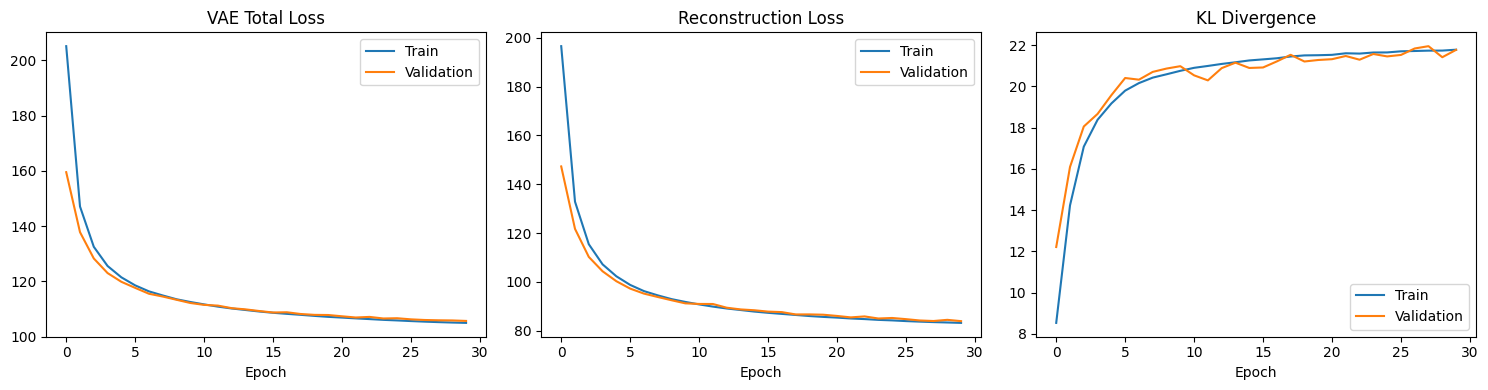

Final VAE validation loss: 105.66 (reconstruction 83.89 + KL 21.77)


In [10]:
h = pd.DataFrame(hist_vae.history)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(h["loss"], label="Train"); ax[0].plot(h["val_loss"], label="Validation"); ax[0].set_title("VAE Total Loss")
ax[1].plot(h["recon_loss"], label="Train"); ax[1].plot(h["val_recon_loss"], label="Validation"); ax[1].set_title("Reconstruction Loss")
ax[2].plot(h["kl_loss"], label="Train"); ax[2].plot(h["val_kl_loss"], label="Validation"); ax[2].set_title("KL Divergence")
for a in ax: a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.show()
print(f"Final VAE validation loss: {h['val_loss'].iloc[-1]:.2f} (reconstruction {h['val_recon_loss'].iloc[-1]:.2f} + KL {h['val_kl_loss'].iloc[-1]:.2f})")

## Step 9: Image Reconstruction – Visual Comparison
Top row: **original** test images. Middle row: **AE** reconstruction. Bottom row: **VAE** reconstruction (the VAE uses the mean μ of the latent distribution, i.e. no random noise).

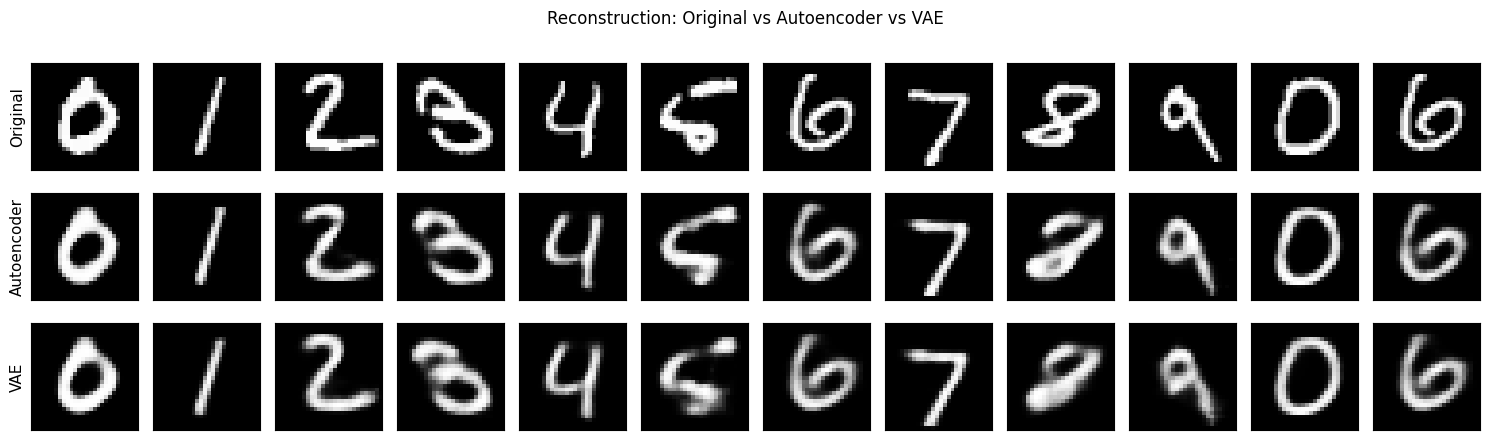

In [11]:
n = 12
idx = [np.where(y_test == d)[0][0] for d in [0,1,2,3,4,5,6,7,8,9]] + [10, 11]   # one image per digit + 2 extra
originals = x_test[idx]

ae_recon  = ae.predict(originals, verbose=0)
z_mean_o, _, _ = vae_encoder.predict(originals, verbose=0)
vae_recon = vae_decoder.predict(z_mean_o, verbose=0)

fig, axes = plt.subplots(3, n, figsize=(15, 4.6))
rows = [("Original", originals), ("Autoencoder", ae_recon), ("VAE", vae_recon)]
for r, (name, imgs) in enumerate(rows):
    for i in range(n):
        axes[r, i].imshow(imgs[i].reshape(28, 28), cmap="gray"); axes[r, i].set_xticks([]); axes[r, i].set_yticks([])
    axes[r, 0].set_ylabel(name, fontsize=11)
plt.suptitle("Reconstruction: Original vs Autoencoder vs VAE"); plt.tight_layout(); plt.show()

### Pixel-wise error maps
Bright pixels show where the reconstruction differs from the original image (|original − reconstruction|).

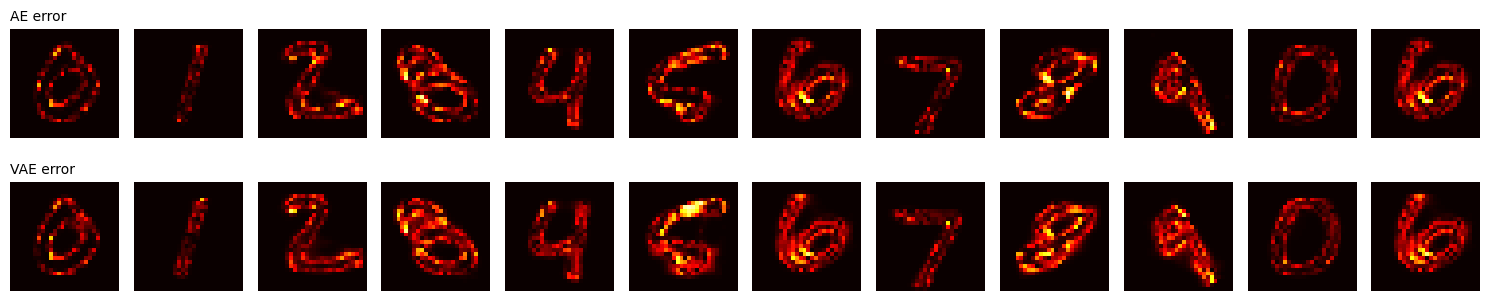

In [12]:
fig, axes = plt.subplots(2, n, figsize=(15, 3.4))
for i in range(n):
    axes[0, i].imshow(np.abs(originals[i] - ae_recon[i]).reshape(28, 28),  cmap="hot", vmin=0, vmax=1); axes[0, i].axis("off")
    axes[1, i].imshow(np.abs(originals[i] - vae_recon[i]).reshape(28, 28), cmap="hot", vmin=0, vmax=1); axes[1, i].axis("off")
axes[0, 0].set_title("AE error", fontsize=10, loc="left"); axes[1, 0].set_title("VAE error", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

## Step 10: Quantitative Reconstruction Metrics (on all 10,000 test images)

| Metric | Meaning | Better |
|---|---|---|
| **MSE** | mean squared pixel error | lower |
| **PSNR** (dB) | peak signal-to-noise ratio | higher |
| **SSIM** | structural similarity between two images (1 = identical) | higher |

In [13]:
def reconstruction_metrics(x_true, x_pred):
    a = tf.reshape(x_true, (-1, 28, 28, 1)); b = tf.reshape(x_pred, (-1, 28, 28, 1))
    mse  = float(tf.reduce_mean(tf.square(a - b)))
    psnr = float(tf.reduce_mean(tf.image.psnr(a, b, max_val=1.0)))
    ssim = float(tf.reduce_mean(tf.image.ssim(a, b, max_val=1.0)))
    return mse, psnr, ssim

ae_test_recon = ae.predict(x_test, batch_size=1000, verbose=0)
zm_test, _, _ = vae_encoder.predict(x_test, batch_size=1000, verbose=0)
vae_test_recon = vae_decoder.predict(zm_test, batch_size=1000, verbose=0)

rows = []
for name, rec in [("Autoencoder", ae_test_recon), ("VAE", vae_test_recon)]:
    mse, psnr, ssim = reconstruction_metrics(x_test, rec)
    rows.append([name, mse, psnr, ssim])
recon_df = pd.DataFrame(rows, columns=["Model", "MSE (lower better)", "PSNR dB (higher better)", "SSIM (higher better)"]).round(4)
recon_df

,Model,MSE (lower better),PSNR dB (higher better),SSIM (higher better)
0,Autoencoder,0.0101,20.9132,0.8793
1,VAE,0.0116,20.1790,0.8551


## Step 11: Image Generation – Sampling Random Latent Vectors
To **generate new images** we throw away the encoder, pick a random latent vector z and feed it to the decoder.

* **VAE:** z ~ N(0, 1) – exactly the distribution the KL term trained the latent space to follow.
* **AE (a):** z ~ N(0, 1) – the same procedure; the AE was never trained to match this distribution.
* **AE (b):** z drawn from a Gaussian fitted to the AE's own latent codes (a more generous baseline for the AE).

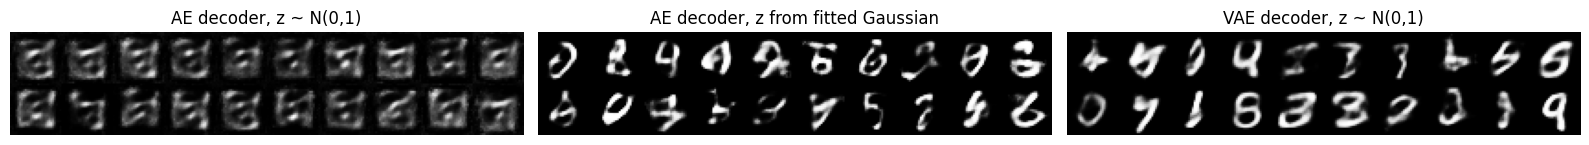

In [14]:
rng = np.random.default_rng(SEED)
N_GEN = 20

# AE (a): z ~ N(0,1)
z_ae_a = rng.standard_normal((N_GEN, LATENT)).astype("float32")
gen_ae_a = ae_decoder.predict(z_ae_a, verbose=0)

# AE (b): z ~ Gaussian fitted to the AE latent codes of the training set
z_codes = ae_encoder.predict(x_train, batch_size=1000, verbose=0)
z_ae_b = (rng.standard_normal((N_GEN, LATENT)) * z_codes.std(0) + z_codes.mean(0)).astype("float32")
gen_ae_b = ae_decoder.predict(z_ae_b, verbose=0)

# VAE: z ~ N(0,1)
z_vae = rng.standard_normal((N_GEN, LATENT)).astype("float32")
gen_vae = vae_decoder.predict(z_vae, verbose=0)

def grid(images, rows, cols):
    canvas = np.zeros((rows * 28, cols * 28))
    for k in range(rows * cols):
        r, c = divmod(k, cols)
        canvas[r*28:(r+1)*28, c*28:(c+1)*28] = images[k].reshape(28, 28)
    return canvas

fig, ax = plt.subplots(1, 3, figsize=(16, 3.4))
for a, imgs, t in zip(ax, [gen_ae_a, gen_ae_b, gen_vae],
                      ["AE decoder, z ~ N(0,1)", "AE decoder, z from fitted Gaussian", "VAE decoder, z ~ N(0,1)"]):
    a.imshow(grid(imgs, 2, 10), cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

### Measuring generation quality objectively
Judging "does this look like a digit?" by eye is subjective, so we use a small **MNIST classifier** as a judge. If a generated image is a clear digit, the classifier will be **confident** (high maximum softmax probability). We generate 2,000 images from each model and report:

* **Mean confidence** – how digit-like the images are (higher is better).
* **% confident (> 0.9)** – share of images the classifier is very sure about.
* **Classes covered** – how many of the 10 digits appear (diversity).

In [15]:
# Train a small judge classifier on real MNIST
clf = keras.Sequential([layers.Input(shape=(784,)), layers.Dense(256, activation="relu"),
                        layers.Dense(128, activation="relu"), layers.Dense(10, activation="softmax")])
clf.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
clf.fit(x_train, y_train, epochs=5, batch_size=256, validation_data=(x_val, y_val), verbose=0)
print("Judge classifier test accuracy: %.4f" % clf.evaluate(x_test, y_test, verbose=0)[1])

M = 2000
zA = rng.standard_normal((M, LATENT)).astype("float32")
zB = (rng.standard_normal((M, LATENT)) * z_codes.std(0) + z_codes.mean(0)).astype("float32")
sets = {
    "AE  (z ~ N(0,1))":          ae_decoder.predict(zA, verbose=0),
    "AE  (z from fitted Gauss)": ae_decoder.predict(zB, verbose=0),
    "VAE (z ~ N(0,1))":          vae_decoder.predict(zA, verbose=0),
    "Real MNIST test images":    x_test[:M],
}
rows = []
for name, imgs in sets.items():
    p = clf.predict(imgs, verbose=0)
    rows.append([name, p.max(1).mean(), (p.max(1) > 0.9).mean() * 100, len(np.unique(p.argmax(1)))])
gen_df = pd.DataFrame(rows, columns=["Generated images from", "Mean confidence", "% confident (>0.9)", "Classes covered (of 10)"]).round(3)
gen_df

Judge classifier test accuracy: 0.9696


,Generated images from,Mean confidence,% confident (>0.9),Classes covered (of 10)
0,"AE (z ~ N(0,1))",0.668,18.05,8
1,AE (z from fitted Gauss),0.772,37.85,10
2,"VAE (z ~ N(0,1))",0.824,50.95,10
3,Real MNIST test images,0.967,90.85,10


## Step 12: Visualising the Latent Space (2-D models)
A 16-D latent space cannot be plotted, so here we train a **second pair of models with only 2 latent dimensions**. Every image becomes a single (x, y) point, coloured by its digit class. This clearly shows the structural difference between AE and VAE latent spaces.

2-D models trained.


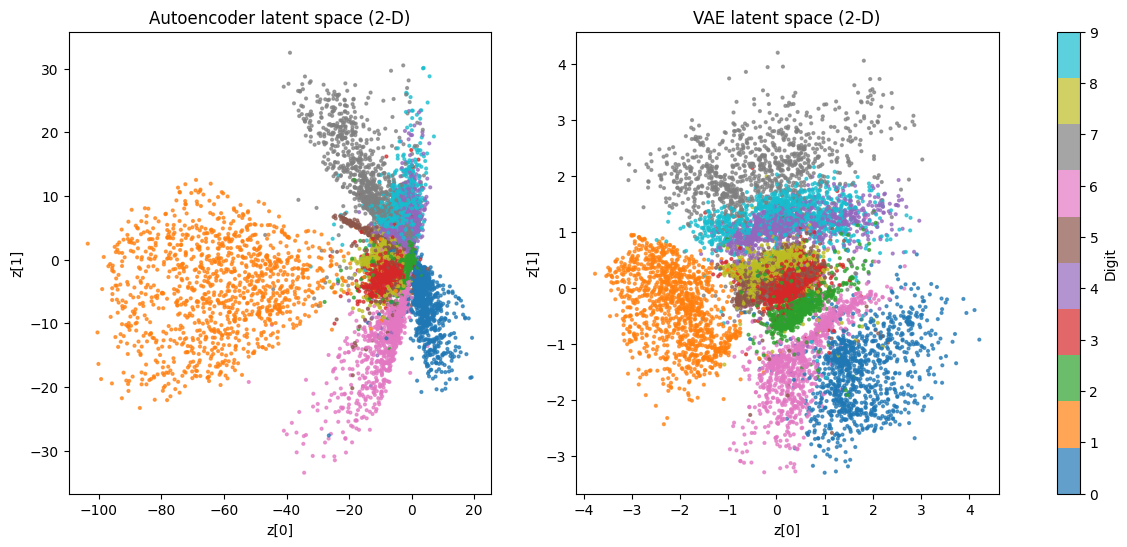

In [16]:
ae2, ae2_enc, ae2_dec = build_autoencoder(2)
ae2.fit(x_train, x_train, epochs=EPOCHS, batch_size=BATCH, shuffle=True, verbose=0)

vae2, vae2_enc, vae2_dec = build_vae(2)
vae2.fit(x_train, x_train, epochs=EPOCHS, batch_size=BATCH, shuffle=True, verbose=0)
print("2-D models trained.")

z_ae2 = ae2_enc.predict(x_test, batch_size=1000, verbose=0)
z_vae2, _, _ = vae2_enc.predict(x_test, batch_size=1000, verbose=0)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, z, t in zip(ax, [z_ae2, z_vae2], ["Autoencoder latent space (2-D)", "VAE latent space (2-D)"]):
    sc = a.scatter(z[:, 0], z[:, 1], c=y_test, cmap="tab10", s=4, alpha=0.7)
    a.set_title(t); a.set_xlabel("z[0]"); a.set_ylabel("z[1]")
fig.colorbar(sc, ax=ax, ticks=range(10), label="Digit")
plt.show()

**How to read this:** the VAE points form a compact, roughly circular cloud centred at the origin (≈ N(0,1)), with neighbouring classes touching smoothly. The AE points are spread over an arbitrary, much larger range with gaps between clusters, so randomly chosen points often land in "empty" regions.

### Latent-space manifold: decoding a regular grid of z values
We decode a 15×15 grid of latent points. For the VAE the grid covers the central region of N(0,1) (using the inverse normal CDF); for the AE it covers the range actually occupied by its latent codes.

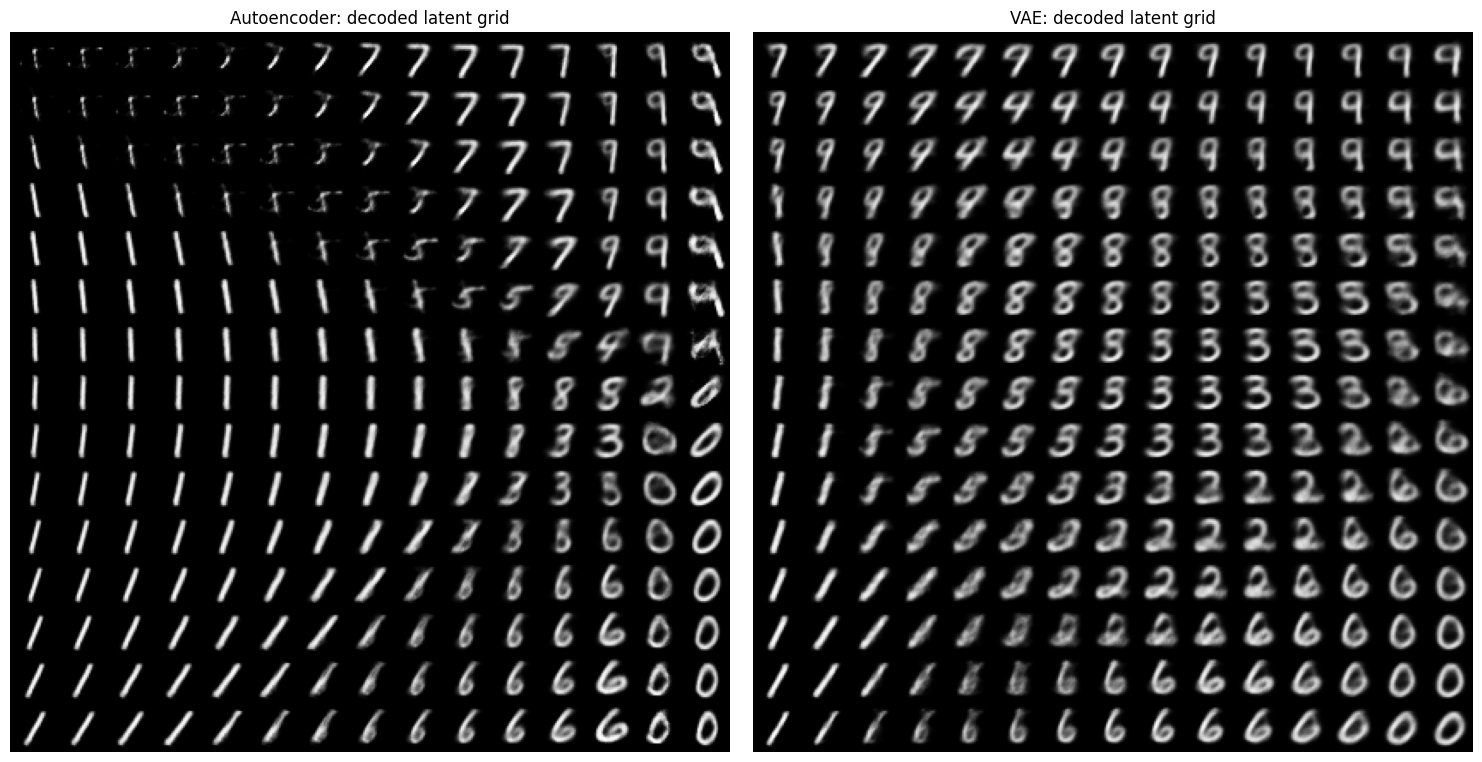

In [17]:
def manifold(decoder, xs, ys, size=28):
    canvas = np.zeros((len(ys) * size, len(xs) * size))
    for i, yv in enumerate(ys[::-1]):
        for j, xv in enumerate(xs):
            img = decoder.predict(np.array([[xv, yv]], dtype="float32"), verbose=0)[0].reshape(size, size)
            canvas[i*size:(i+1)*size, j*size:(j+1)*size] = img
    return canvas

G = 15
vae_axis = norm.ppf(np.linspace(0.05, 0.95, G))
ae_x = np.linspace(*np.percentile(z_ae2[:, 0], [2, 98]), G)
ae_y = np.linspace(*np.percentile(z_ae2[:, 1], [2, 98]), G)

fig, ax = plt.subplots(1, 2, figsize=(15, 7.5))
ax[0].imshow(manifold(ae2_dec, ae_x, ae_y), cmap="gray");  ax[0].set_title("Autoencoder: decoded latent grid")
ax[1].imshow(manifold(vae2_dec, vae_axis, vae_axis), cmap="gray"); ax[1].set_title("VAE: decoded latent grid")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## Step 13: Latent-Space Interpolation
We encode two different digits (here a **3** and a **8**) and decode points on the straight line between their latent codes. A good latent space produces a **smooth morph** from one digit to the other.

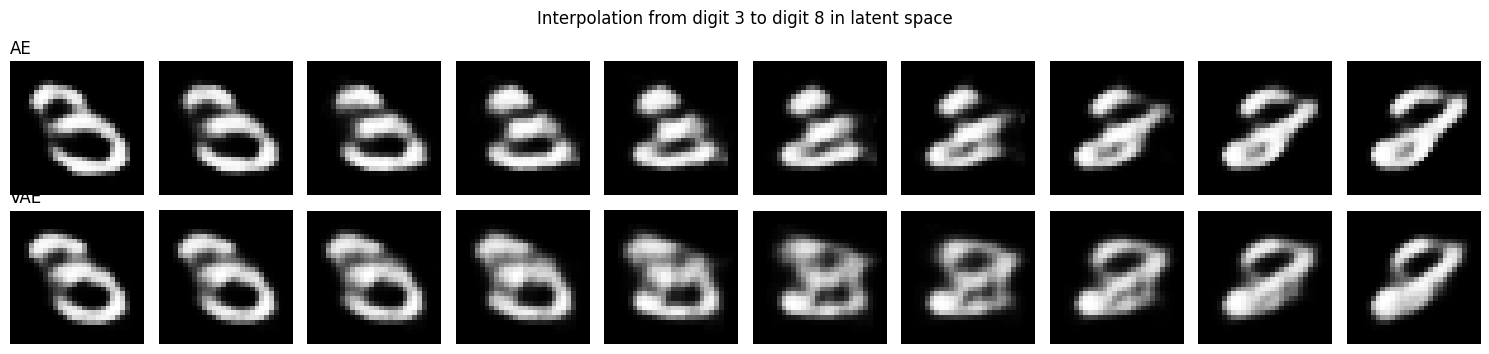

In [18]:
a_idx = np.where(y_test == 3)[0][0]; b_idx = np.where(y_test == 8)[0][0]
xa, xb = x_test[a_idx:a_idx+1], x_test[b_idx:b_idx+1]
steps = np.linspace(0, 1, 10)[:, None].astype("float32")

# AE interpolation
za, zb = ae_encoder.predict(xa, verbose=0), ae_encoder.predict(xb, verbose=0)
interp_ae = ae_decoder.predict((1 - steps) * za + steps * zb, verbose=0)

# VAE interpolation (using the means)
za, zb = vae_encoder.predict(xa, verbose=0)[0], vae_encoder.predict(xb, verbose=0)[0]
interp_vae = vae_decoder.predict((1 - steps) * za + steps * zb, verbose=0)

fig, axes = plt.subplots(2, 10, figsize=(15, 3.6))
for i in range(10):
    axes[0, i].imshow(interp_ae[i].reshape(28, 28),  cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(interp_vae[i].reshape(28, 28), cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_title("AE", loc="left"); axes[1, 0].set_title("VAE", loc="left")
plt.suptitle("Interpolation from digit 3 to digit 8 in latent space"); plt.tight_layout(); plt.show()

## Step 14: Final Comparison Summary

In [19]:
summary = pd.DataFrame({
    "Criterion": ["Reconstruction MSE (lower better)", "Reconstruction PSNR dB (higher better)", "Reconstruction SSIM (higher better)",
                  "Generation: mean classifier confidence", "Generation: % confident images"],
    "Autoencoder": [recon_df.iloc[0, 1], recon_df.iloc[0, 2], recon_df.iloc[0, 3],
                    gen_df.iloc[0, 1], gen_df.iloc[0, 2]],
    "VAE":         [recon_df.iloc[1, 1], recon_df.iloc[1, 2], recon_df.iloc[1, 3],
                    gen_df.iloc[2, 1], gen_df.iloc[2, 2]],
})
print("(Autoencoder generation scores use z ~ N(0,1), the same sampling as the VAE.)\n")
summary

(Autoencoder generation scores use z ~ N(0,1), the same sampling as the VAE.)



,Criterion,Autoencoder,VAE
0,Reconstruction MSE (lower better),0.0101,0.0116
1,Reconstruction PSNR dB (higher better),20.9132,20.1790
2,Reconstruction SSIM (higher better),0.8793,0.8551
3,Generation: mean classifier confidence,0.6680,0.8240
4,Generation: % confident images,18.0500,50.9500


## Step 15: Conclusion

**1. Reconstruction – the Autoencoder is slightly better.**
On the 10,000 test images the AE reached MSE 0.0101, PSNR 20.91 dB and SSIM 0.879, against 0.0116, 20.18 dB and 0.855 for the VAE. The AE only has to minimise reconstruction error, while the VAE must also satisfy the KL term, which adds noise and smoothing; its digits are therefore a little blurrier, especially for hard shapes such as 3, 5 and 8.

**2. Generation – the VAE is clearly better.**
When random vectors z ~ N(0,1) are decoded, the AE produces mostly noisy, texture-like blobs (mean classifier confidence 0.668, only 18% of images confident, 8 of 10 digits appear). The VAE produces recognisable digits (confidence 0.824, 51% confident, all 10 digits appear). Even when the AE is given the easier task of sampling from a Gaussian fitted to its own latent codes, it reaches only 0.772 / 38%, still below the VAE. Real MNIST images score 0.967 / 91%, so VAE samples are good but not perfect.

**3. Latent space.**
The 2-D plots show why. The AE places digits over a huge, irregular range (z[0] spans roughly −100 to +20) with large empty regions between clusters, so a random z usually lands where the decoder was never trained. The VAE latent space is a compact cloud centred on 0 (about ±4), matching N(0,1), and every region of the decoded grid contains a digit-like image that changes gradually with z.

**4. Interpolation.**
Moving between the codes of a 3 and an 8 produces a gradual change of shape for both models. Because the VAE latent space is regularised, its in-between points are valid latent points, which is what makes it useful for generation.

| | Autoencoder | Variational Autoencoder |
|---|---|---|
| Reconstruction quality | **Better** (lower MSE, higher PSNR/SSIM) | Slightly blurrier |
| Random generation | Poor | **Good** |
| Latent space | Irregular, gaps | Smooth, compact N(0,1) |
| Best used for | Compression, denoising, feature learning | Generating new data, smooth latent exploration |

**Limitations and possible improvements:** simple fully-connected networks were trained for only 30 epochs on MNIST; convolutional encoders/decoders, a larger latent size, more epochs, or a β-VAE (changing the weight of the KL term to trade reconstruction against generation quality) would give sharper images. Exact numbers vary by a small amount from run to run because of random initialisation.

**Result:** An Autoencoder and a Variational Autoencoder were built, trained and compared; the AE is better at reconstruction, while the VAE is better at generating new images.